# Task 1 : Multi-class Benchmark Classification Pipline (iris / Wine)

## - Import the library and load the dataset

In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression 
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix

In [93]:
data = pd.read_csv('iris.csv')

## - EDA (Explore Data Analysis)

In [94]:
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [95]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [96]:
data.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### - Perform exploratory pairplots

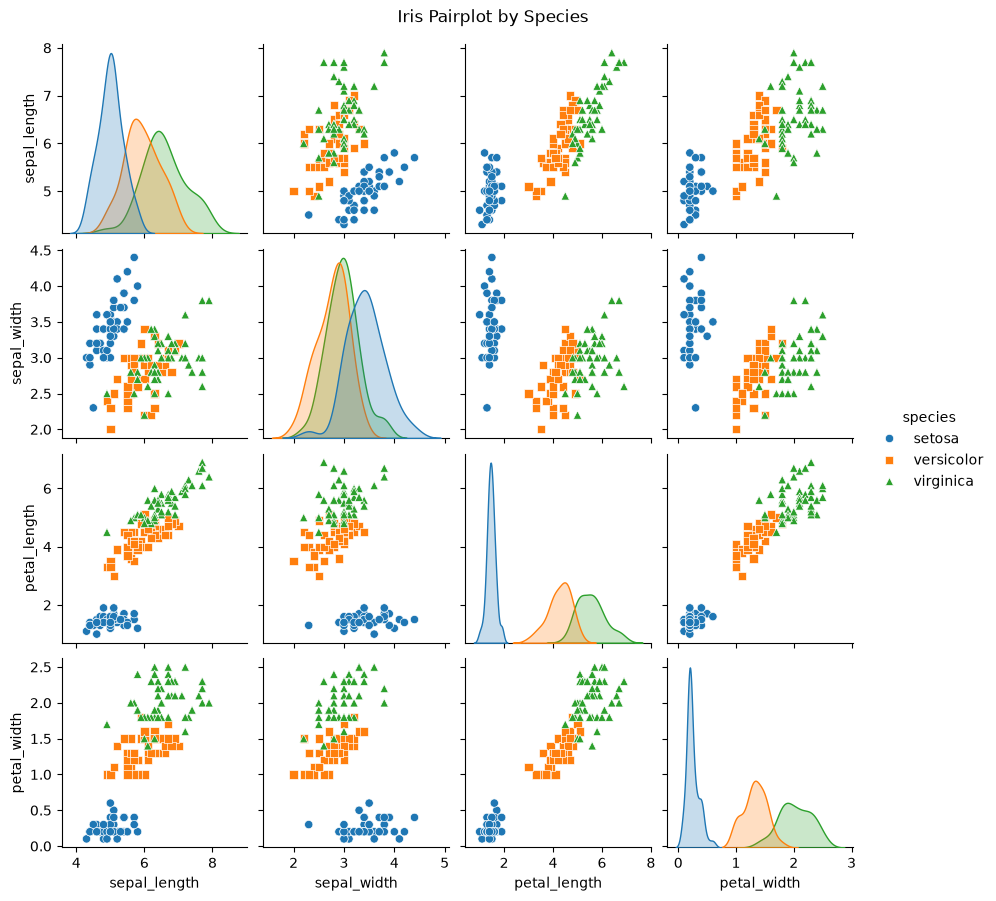

In [97]:
sns.pairplot(
    data,
    hue='species',
    diag_kind='kde',
    markers=['o', 's', '^'],
    height=2.2
)
plt.suptitle('Iris Pairplot by Species', y=1.02)
plt.show()

## Normalize features using StandardScaler()

In [98]:
x = data.drop('species',axis=1)
y = data['species']

In [99]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.2,
                                                    random_state=42 ,
                                                    stratify =y)

In [100]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

## Train LogisticRegression and DecisionTreeClassifier

In [101]:
""" Models Evaluations """
print("Classification Report")
model_1 = LogisticRegression(max_iter=200, random_state=42)
model_2 = DecisionTreeClassifier(random_state=42)

# training the first model (Logistic Regression)
model_1.fit(x_train_scaled, y_train)
y_predection_lr = model_1.predict(x_test_scaled)
print(f"- Training the LogisticRegression Model : ")
print(f"The accuracy score : {accuracy_score(y_test, y_predection_lr)}")
print(f"The precision score : {precision_score(y_test, y_predection_lr, average='weighted')}")
print(f"The recall score : {recall_score(y_test, y_predection_lr, average='weighted')}")
print(f"The f1 score : {f1_score(y_test, y_predection_lr, average='weighted')}")
print('-----------------------------------------')

# training the second model (Decision Tree)
print(f"- Training the DecisionTreeClassifier Model : ")
model_2.fit(x_train_scaled, y_train)
y_predection_dt = model_2.predict(x_test_scaled)
print(f"The accuracy score : {accuracy_score(y_test, y_predection_dt)}")
print(f"The precision score : {precision_score(y_test, y_predection_dt, average='weighted')}")
print(f"The recall score : {recall_score(y_test, y_predection_dt, average='weighted')}")
print(f"The f1 score : {f1_score(y_test, y_predection_dt, average='weighted')}")

Classification Report
- Training the LogisticRegression Model : 
The accuracy score : 0.9333333333333333
The precision score : 0.9333333333333333
The recall score : 0.9333333333333333
The f1 score : 0.9333333333333333
-----------------------------------------
- Training the DecisionTreeClassifier Model : 
The accuracy score : 0.9333333333333333
The precision score : 0.9333333333333333
The recall score : 0.9333333333333333
The f1 score : 0.9333333333333333


## Plot the confusion matrix heatmap and plot the decision boundary visualization

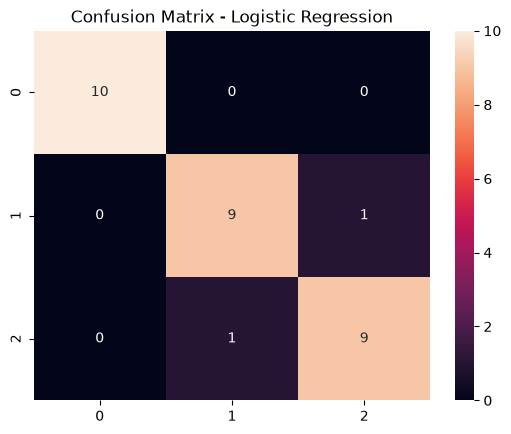

In [102]:
cf_matrix = confusion_matrix(y_test, y_predection_lr)
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cf_matrix, annot=True)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

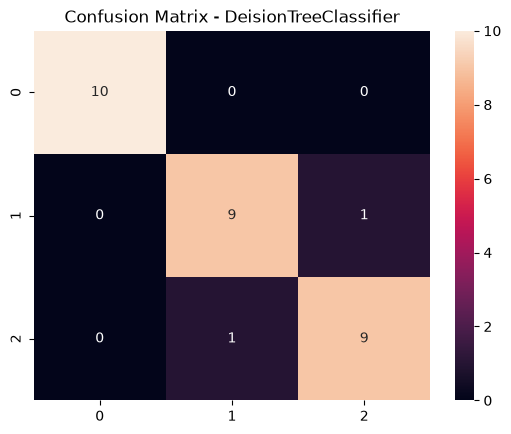

In [103]:
cf_matrix = confusion_matrix(y_test, y_predection_dt)
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cf_matrix, annot=True)
plt.title("Confusion Matrix - DeisionTreeClassifier")
plt.show()

In [104]:
X_train_2d = x_train_scaled[:, [2, 3]]

y_train_codes = y_train.astype('category').cat.codes

xx, yy = np.meshgrid(
    np.linspace(X_train_2d[:, 0].min() - 0.8, X_train_2d[:, 0].max() + 0.8, 300),
    np.linspace(X_train_2d[:, 1].min() - 0.8, X_train_2d[:, 1].max() + 0.8, 300)
)
grid_points = np.c_[xx.ravel(), yy.ravel()]

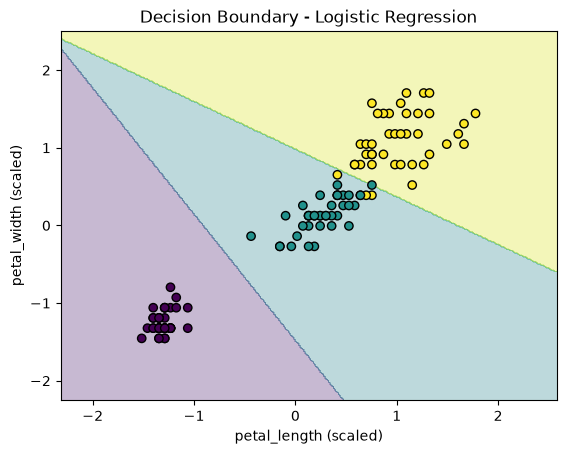

In [105]:
lr_2d = LogisticRegression(max_iter=200, random_state=42)
lr_2d.fit(X_train_2d, y_train_codes)

Z_lr = lr_2d.predict(grid_points).reshape(xx.shape)

plt.contourf(xx, yy, Z_lr, alpha=0.3, cmap='viridis')
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train_codes, cmap='viridis', edgecolor='k')
plt.title("Decision Boundary - Logistic Regression")
plt.xlabel("petal_length (scaled)")
plt.ylabel("petal_width (scaled)")
plt.show()

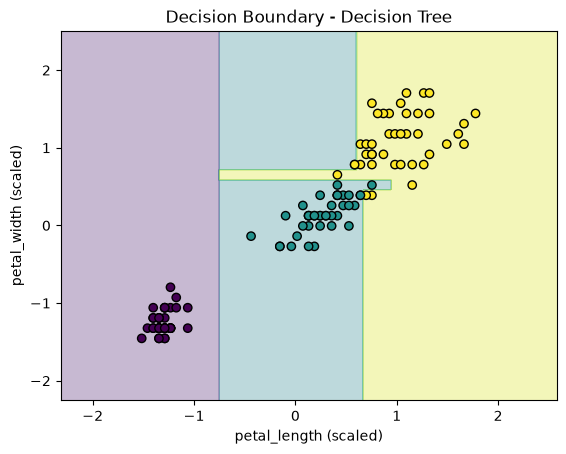

In [106]:
dt_2d = DecisionTreeClassifier(random_state=42)
dt_2d.fit(X_train_2d, y_train_codes)

Z_dt = dt_2d.predict(grid_points).reshape(xx.shape)

plt.contourf(xx, yy, Z_dt, alpha=0.3, cmap='viridis')
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train_codes, cmap='viridis', edgecolor='k')
plt.title("Decision Boundary - Decision Tree")
plt.xlabel("petal_length (scaled)")
plt.ylabel("petal_width (scaled)")
plt.show()